<a href="https://colab.research.google.com/github/Susmithavura/AI_CAPSTONE_PROJECT_BATCH-3/blob/main/College_RAG_Chatbot_fixed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎓 Retrieval-Augmented Generation (RAG) Chatbot for College Regulations and Syllabus Queries
## Section 1 – Project Introduction
**Problem statement:** College rules (attendance, exams, grading, fees, hostel, library) and the first-semester syllabus are scattered across many documents. Students cannot find answers quickly, staff repeat the same answers, and general chatbots may hallucinate wrong rules.

**Objectives**
1. Build a clean, categorised question-answer knowledge base (`college_rag_qa.csv`).
2. Retrieve the most relevant stored answer with a **hybrid retriever**: TF-IDF words + character 3–5-grams + MiniLM embeddings (FAISS).
3. Refuse unrelated questions using a **validated confidence threshold**.
4. Evaluate honestly (Top-1, Top-3, precision, recall, F1, rejection accuracy, latency).

**Architecture:** `Query → clean → [S_word, S_char, S_sem] → S_final = w_word·S_word + w_char·S_char + w_sem·S_sem → best match → confidence ≥ threshold? → stored CSV answer / "not available"`

**Technologies:** Python, pandas, NumPy, scikit-learn, sentence-transformers (MiniLM), FAISS, matplotlib, seaborn, ipywidgets.

> ⚠️ **Important:** The regulations (75 % attendance etc.) and the first-semester syllabus in the CSV are **SAMPLE data** (see the `policy_status` column). Replace them with your official college documents before real use. No LLM is used to invent rules – every answer comes from the CSV.

## Section 2 – Install Dependencies

In [4]:
# Colab already has pandas/numpy/sklearn/matplotlib/seaborn. Install the rest quietly.
!pip -q install sentence-transformers faiss-cpu ipywidgets

In [5]:
import os, re, time, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Optional heavy libraries: the notebook degrades gracefully if they are missing.
try:
    import faiss; HAS_FAISS = True
except Exception: HAS_FAISS = False
try:
    from sentence_transformers import SentenceTransformer; HAS_ST = True
except Exception: HAS_ST = False
print("FAISS available:", HAS_FAISS, "| MiniLM available:", HAS_ST)

# ---------------- global configuration ----------------
CSV_PATH    = "college_rag_qa.csv"
INSTITUTION = "B.Tech Engineering College"   # main prototype focus
SEED        = 42
NOT_FOUND_MSG = "Sorry, this information is not available in the current college knowledge base. Please contact the Academic Office."

FAISS available: True | MiniLM available: True


## Section 3 – Dataset Loading
Upload `college_rag_qa.csv` when asked (or place it next to the notebook).

In [3]:
import glob
def load_dataset(path=CSV_PATH):
    # Find the CSV under ANY file name (e.g. 'Document from Susmitha vura'); otherwise ask for an upload.
    if not os.path.exists(path):
        cands = [f for f in glob.glob("*.csv") + glob.glob("/content/*.csv") if "rag_artifacts" not in f]
        if cands:
            path = max(cands, key=os.path.getsize); print("Using CSV found at:", path)
        else:
            try:
                from google.colab import files
                print("Please upload your college_rag_qa.csv file (any file name is fine)")
                up = files.upload(); path = list(up.keys())[0]
            except ImportError:
                raise FileNotFoundError("CSV not found. Put it in the same folder as this notebook.")
    df = pd.read_csv(path)
    needed = {"fact_id","institution_type","category","semester","subject","unit","question","answer","source_type","policy_status"}
    missing = needed - set(df.columns)
    if missing: raise ValueError(f"CSV is missing columns: {missing}. Did you upload the right file (not the .ipynb)?")
    if "question_style" not in df.columns: df["question_style"] = "unknown"
    return df
raw = load_dataset()
print("Dimensions (all institutions):", raw.shape)
kb = raw[raw.institution_type == INSTITUTION].reset_index(drop=True)
print("B.Tech knowledge base used by the chatbot:", kb.shape)
display(kb.head(10))
print("\nCategory distribution:"); display(kb.category.value_counts())
print("Missing values per column:"); display(raw.isna().sum())
print("Duplicate questions:", raw.question.str.lower().duplicated().sum(), "| duplicate Q-A pairs:", raw.duplicated(["question","answer"]).sum())

Please upload your college_rag_qa.csv file (any file name is fine)


Saving college_rag_qa (1).csv to college_rag_qa (1).csv
Dimensions (all institutions): (5188, 13)
B.Tech knowledge base used by the chatbot: (5092, 13)


,id,fact_id,institution_type,category,subcategory,semester,subject,unit,question,answer,question_style,source_type,policy_status
0,1,F0183,B.Tech Engineering College,Syllabus,concept: schrodinger,1,Engineering Physics,3.0,please tell me what is Schrodinger equation (e...,Time-independent Schrodinger equation: d^2 psi...,informal,sample_syllabus,SAMPLE - replace with official syllabus
1,2,F0042,B.Tech Engineering College,Academic Regulations,grading system,All,NaN,NaN,doubt: what is the grading system as per colle...,Sample grading scale (out of 100): O = 90-100 ...,informal,sample_policy,SAMPLE - replace with official regulation
2,3,F0056,B.Tech Engineering College,College Administration,ID card,All,NaN,NaN,How to get duplicate ID card?,New ID cards are issued by the college office ...,canonical,sample_policy,SAMPLE - replace with official regulation
3,4,F0183,B.Tech Engineering College,Syllabus,concept: schrodinger,1,Engineering Physics,3.0,Bro What is Schrodinger equation please,Time-independent Schrodinger equation: d^2 psi...,informal,sample_syllabus,SAMPLE - replace with official syllabus
4,5,F0063,B.Tech Engineering College,College Administration,lost library book,All,NaN,NaN,One doubt: fine for losing libarary book asap,Sample rule: inform the librarian immediately....,informal+typo,sample_policy,SAMPLE - replace with official regulation
5,6,F0158,B.Tech Engineering College,Syllabus,Engineering Graphics unit 3,1,Engineering Graphics,3.0,What is Unit 3 in graphics syllabus?,Engineering Graphics - Unit 3: Projection of p...,canonical,sample_syllabus,SAMPLE - replace with official syllabus
6,7,F0071,B.Tech Engineering College,Practical Student Problems,forgot ID card,All,NaN,NaN,"Can you tell me i forgot my ID card, can I ent...",Report to the security or college office; you ...,informal,sample_policy,SAMPLE - replace with official regulation
7,8,F0170,B.Tech Engineering College,Syllabus,Engineering Workshop credits and code,1,Engineering Workshop,NaN,"hello, workshop course code ?",Engineering Workshop has placeholder code SAMP...,informal,sample_syllabus,SAMPLE - replace with official syllabus
8,9,F0120,B.Tech Engineering College,Syllabus,Engineering Physics unit 5,1,Engineering Physics,5.0,doubt: what is unit 5 in eng physics syllabus ...,Engineering Physics - Unit 5: Magnetic materia...,informal,sample_syllabus,SAMPLE - replace with official syllabus
9,10,F0159,B.Tech Engineering College,Syllabus,Engineering Graphics unit 4,1,Engineering Graphics,4.0,graphics unit 4 topics,Engineering Graphics - Unit 4: Sections and de...,canonical,sample_syllabus,SAMPLE - replace with official syllabus



Category distribution:


,count
category,
Syllabus,2572
Examination,630
Academic Regulations,480
College Administration,480
Attendance,480
Practical Student Problems,450


Missing values per column:


,0
id,0
fact_id,0
institution_type,0
category,0
subcategory,0
semester,96
subject,2856
unit,3716
question,0
answer,0


Duplicate questions: 0 | duplicate Q-A pairs: 0


## Section 4 – Exploratory Data Analysis

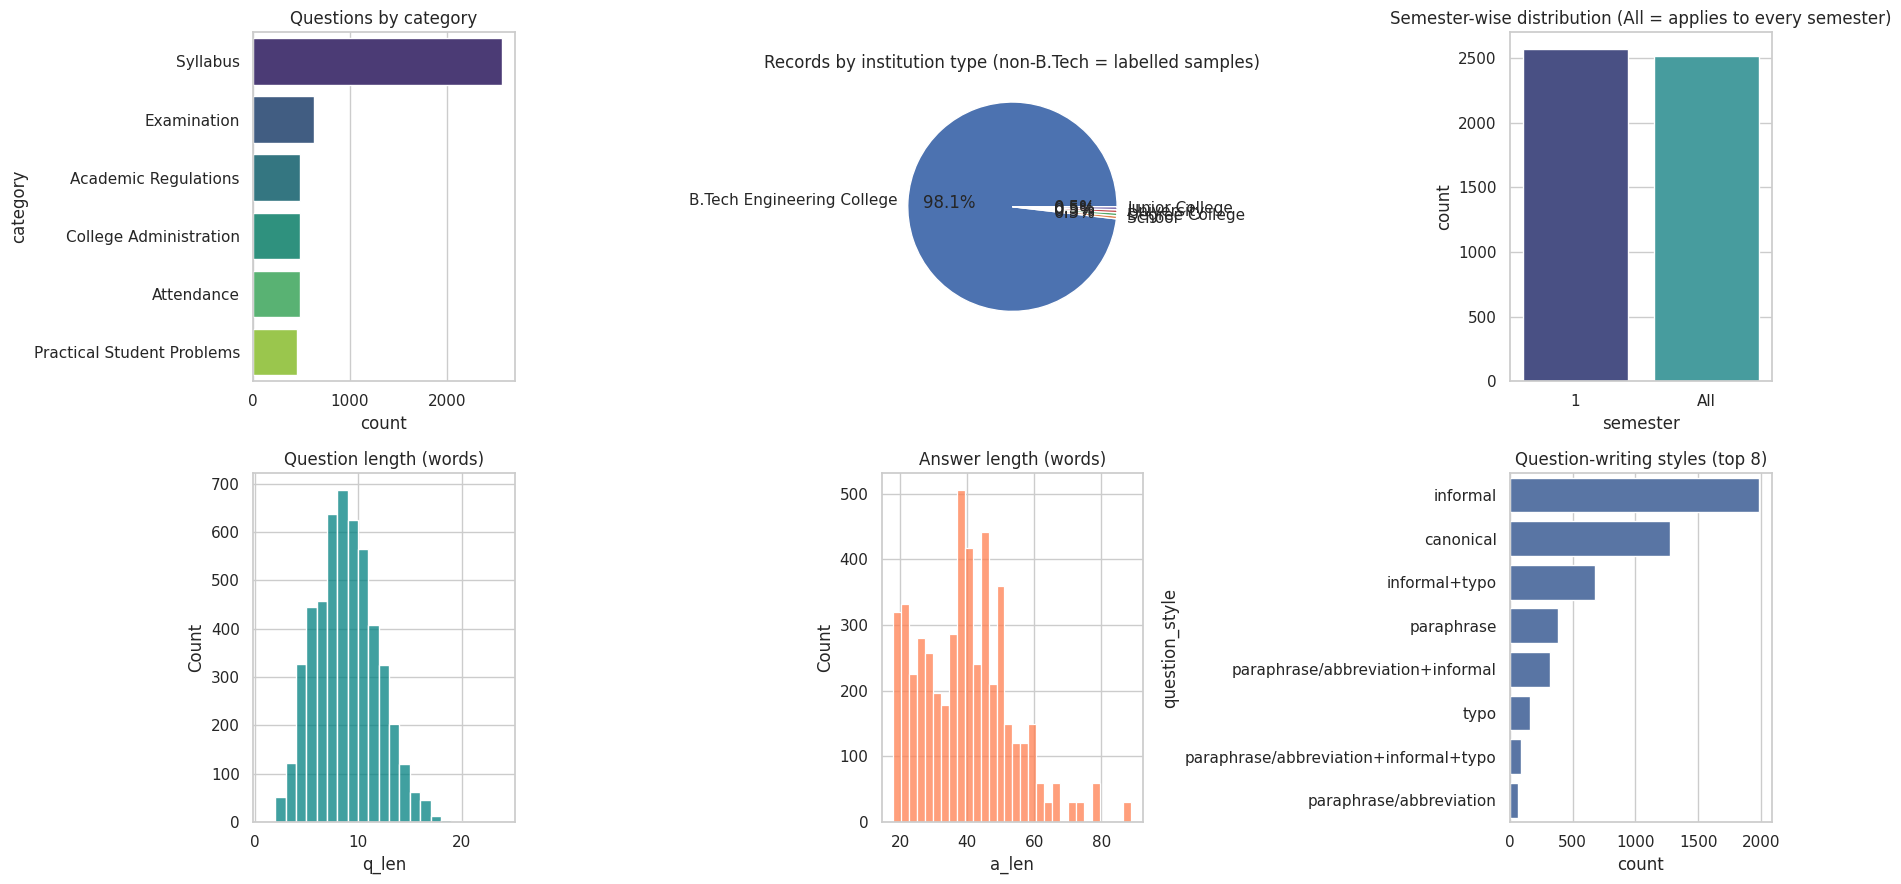

Unique answers (facts): 188 | avg. question variants per fact: 27.1


In [6]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
order = kb.category.value_counts().index
sns.countplot(y="category", data=kb, order=order, ax=ax[0,0], palette="viridis"); ax[0,0].set_title("Questions by category")
raw.institution_type.value_counts().plot.pie(autopct="%1.1f%%", ax=ax[0,1]); ax[0,1].set_ylabel(""); ax[0,1].set_title("Records by institution type (non-B.Tech = labelled samples)")
sns.countplot(x="semester", data=kb, ax=ax[0,2], palette="mako"); ax[0,2].set_title("Semester-wise distribution (All = applies to every semester)")
kb["q_len"] = kb.question.str.split().str.len(); kb["a_len"] = kb.answer.str.split().str.len()
sns.histplot(kb.q_len, bins=range(1,25), ax=ax[1,0], color="teal"); ax[1,0].set_title("Question length (words)")
sns.histplot(kb.a_len, bins=30, ax=ax[1,1], color="coral"); ax[1,1].set_title("Answer length (words)")
sns.countplot(y="question_style", data=kb, ax=ax[1,2], order=kb.question_style.value_counts().index[:8]); ax[1,2].set_title("Question-writing styles (top 8)")
plt.tight_layout(); plt.show()
print("Unique answers (facts):", kb.fact_id.nunique(), "| avg. question variants per fact:", round(len(kb)/kb.fact_id.nunique(),1))

## Section 5 – Text Preprocessing
Lower-casing, whitespace/punctuation normalisation, filler removal (`please`, `sir`, `bro`…), student abbreviations expanded (`sem → semester`, `reval → revaluation`). Technical terms such as **CGPA, SGPA, 75%, unit numbers** are preserved (`%` becomes the word *percent*).

In [18]:
ABBR = {"sem":"semester","sems":"semester","exams":"exam","examination":"exam","examinations":"exam","min":"minimum","max":"maximum",
        "reval":"revaluation","supply":"supplementary","suply":"supplementary","laboratory":"lab","maths":"mathematics","math":"mathematics",
        "phy":"physics","chem":"chemistry","dept":"department","cert":"certificate","info":"information","u":"you","ur":"your","r":"are",
        "wat":"what","whats":"what is","subs":"subjects","subjects":"subject","att":"attendance","attn":"attendance","regs":"regulations","pps":"programming for problem solving"}
FILLER_PHRASES = [r"\bi want to know\b", r"\bcan you tell me\b", r"\bquick question\b", r"\bplease tell( me)?\b", r"\bone doubt\b", r"\bi have a doubt\b", r"\bdoubt\b", r"\btell me\b"]
FILLER_WORDS  = {"please","pls","plz","sir","madam","bro","hi","hello","hey","kindly","asap"}

def clean_text(text: str) -> str:
    # Normalise a query/question for matching; keep numbers and technical terms.
    t = str(text).lower()
    t = t.replace("%", " percent ")
    t = re.sub(r"unit\s*(\d)", r"unit \1", t)            # unit1 -> unit 1
    for p in FILLER_PHRASES: t = re.sub(p, " ", t)
    t = re.sub(r"[^a-z0-9\s]", " ", t)                    # punctuation -> space
    toks = [ABBR.get(w, w) for w in t.split() if w not in FILLER_WORDS]
    out = " ".join(toks).strip()
    return out if out else str(text).lower().strip()

for q in ["Pls tell me min attendence for sem exams??", "I have 72% attendance, can I write exam", "unit1 of maths"]:
    print(q, "->", clean_text(q))

Pls tell me min attendence for sem exams?? -> minimum attendence for semester exam
I have 72% attendance, can I write exam -> i have 72 percent attendance can i write exam
unit1 of maths -> unit 1 of mathematics


## Section 6 – Hybrid Retrieval Algorithm
$$S_{final} = w_{word}\,S_{word} + w_{char}\,S_{char} + w_{sem}\,S_{sem}$$
* `S_word` – TF-IDF (1–2 word n-grams) cosine similarity
* `S_char` – TF-IDF on character 3–5-grams (`char_wb`) cosine similarity (robust to typos)
* `S_sem` – MiniLM (`all-MiniLM-L6-v2`) sentence embeddings, unit-normalised, searched with a FAISS inner-product index (= cosine)

Weights and threshold are **configurable** and selected experimentally on a validation set (Section 7) – they are not assumed optimal.

In [19]:
class HybridRetriever:
    # Hybrid TF-IDF + char n-gram + MiniLM/FAISS retriever over stored questions.
    def __init__(self, weights=(0.3, 0.4, 0.3), model_name="sentence-transformers/all-MiniLM-L6-v2"):
        self.weights, self.model_name = tuple(weights), model_name

    def fit(self, questions):
        self.clean_q = [clean_text(q) for q in questions]
        self.word_vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
        self.char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)
        self.Xw = self.word_vec.fit_transform(self.clean_q)
        self.Xc = self.char_vec.fit_transform(self.clean_q)
        self.use_dense = HAS_ST
        if self.use_dense:
            try:
                self.encoder = SentenceTransformer(self.model_name)
                self.E = self._embed(self.clean_q)
                if HAS_FAISS:
                    self.index = faiss.IndexFlatIP(self.E.shape[1]); self.index.add(self.E)
            except Exception as ex:      # model download / memory problem -> keep working without MiniLM
                print("MiniLM could not be loaded (", type(ex).__name__, ") -> using word + char scores only.")
                self.use_dense = False
        if not self.use_dense:
            print("MiniLM not available -> running with word + char scores only (weights renormalised).")
        return self

    def _embed(self, texts):
        return self.encoder.encode(list(texts), normalize_embeddings=True, show_progress_bar=False).astype("float32")

    def score_matrices(self, queries):
        # Return (S_word, S_char, S_sem), each of shape (n_queries, n_kb_questions) on a 0-1 cosine scale.
        cq = [clean_text(q) for q in queries]
        Sw = (self.word_vec.transform(cq) @ self.Xw.T).toarray()
        Sc = (self.char_vec.transform(cq) @ self.Xc.T).toarray()
        if self.use_dense:
            Eq = self._embed(cq); n = self.E.shape[0]
            if HAS_FAISS:
                D, I = self.index.search(Eq, n)                 # FAISS vector search (all neighbours)
                Ss = np.zeros_like(D); np.put_along_axis(Ss, I, D, axis=1)
            else:
                Ss = Eq @ self.E.T
            Ss = np.clip(Ss, 0, 1)
        else:
            Ss = np.zeros_like(Sw)
        return Sw, Sc, Ss

    def combine(self, Sw, Sc, Ss, weights=None):
        w = np.array(weights or self.weights, dtype=float)
        if not self.use_dense: w[2] = 0
        w = w / w.sum()                                        # weights always sum to 1 -> score stays in 0-1
        return w[0]*Sw + w[1]*Sc + w[2]*Ss

    def search(self, query, k=3, weights=None):
        S = self.combine(*self.score_matrices([query]), weights)[0]
        top = np.argsort(-S)[:k]
        return top, S[top]

## Section 7 – Confidence and Relevance Checking
Protocol (honest evaluation):
1. Each fact has many question variants. Per fact we hold out ~15 % variants for **validation** and ~15 % for **test**; the index contains only the remaining **train** variants.
2. **Unrelated queries** (weather, cricket, … plus *hard negatives* such as college-sounding questions that are not in the KB) are split into validation/test too.
3. Weights and threshold are tuned on **validation only**, then reported once on **test**.

In [9]:
def split_by_fact(df, val_frac=0.15, test_frac=0.15, seed=SEED):
    rng = np.random.RandomState(seed); split = np.array(["train"] * len(df), dtype=object)
    for fid, idx in df.groupby("fact_id").indices.items():
        if len(idx) >= 8:
            idx = rng.permutation(idx); nv = max(1, int(len(idx)*val_frac)); nt = max(1, int(len(idx)*test_frac))
            split[idx[:nv]] = "val"; split[idx[nv:nv+nt]] = "test"
    return split
kb["split"] = split_by_fact(kb)
print(kb.split.value_counts().to_dict())

OOD = ["What is the weather today?","Who won the cricket match yesterday?","How do I bake a chocolate cake?","What is the capital of France?","Tell me a joke","Who is the prime minister of India?",
"Best smartphone under 20000","How to lose weight fast?","Latest movie releases this week","What is the price of petrol today?","Explain quantum computing in simple words","How to learn guitar?",
"Which is the tallest mountain in the world?","How do I book a train ticket?","What is bitcoin price?","Write a poem about love","How to make biryani?","Who is the richest person in the world?",
"What is the meaning of life?","Recommend a good web series","How to fix a flat bicycle tyre?","What is the stock price of Tesla?","Translate hello into Spanish","Who invented the telephone?",
"When is the next IPL match?","How far is the moon from earth?","Which actor is the best in Tollywood?","How to apply for a passport?","Tell me about the Mughal empire","What is the best programming language for AI jobs?",
"What is the mess menu on Sunday?","What was the placement package of CSE last year?","Which cafeteria item is cheapest?","When is the college annual day fest?","What is the principal's phone number?",
"Does the college have a swimming pool?","What is the cut-off rank for EAMCET admission?","How many seats are there in ECE?","Is there wifi in the hostel rooms?","What is the dress code for college fest?",
"What are the subjects in the fifth semester?","What is Unit 3 of Machine Learning?","What is the syllabus of Data Structures?","Explain the syllabus of Operating Systems unit 2","Who is the HOD of Mechanical department?",
"How to get a visa for studying abroad?","What is the GATE exam syllabus?","How to prepare for civil services?","Which company visits campus for placements?","Can I get a refund for my gym membership?",
"How do I reset my Instagram password?","What is the speed of light?","Describe photosynthesis","How do airplanes fly?","What is the population of India?","Give me a recipe for pasta","Who wrote Hamlet?","How to start a YouTube channel?","What is the best laptop for gaming?","Where is the nearest hospital?"]
rng = np.random.RandomState(SEED); perm = rng.permutation(len(OOD))
ood_val  = [OOD[i] for i in perm[: len(OOD)//2]]
ood_test = [OOD[i] for i in perm[len(OOD)//2 :]]
print("Unrelated queries -> val:", len(ood_val), "test:", len(ood_test))

train = kb[kb.split == "train"].reset_index(drop=True)
val   = kb[kb.split == "val"].reset_index(drop=True)
test  = kb[kb.split == "test"].reset_index(drop=True)
t0 = time.time(); eval_ret = HybridRetriever().fit(train.question.tolist()); print(f"Index built on {len(train)} questions in {time.time()-t0:.1f}s")

{'train': 3718, 'test': 687, 'val': 687}
Unrelated queries -> val: 30 test: 30


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Index built on 3718 questions in 49.0s


Top 8 weight settings on validation:


,w_word,w_char,w_sem,top1,top3
0,0.0,0.1,0.9,0.947598,0.979622
1,0.0,0.2,0.8,0.946143,0.975255
2,0.0,0.0,1.0,0.944687,0.981077
3,0.1,0.1,0.8,0.944687,0.973799
4,0.1,0.0,0.9,0.941776,0.973799
5,0.0,0.3,0.7,0.940320,0.972344
6,0.2,0.0,0.8,0.940320,0.972344
7,0.0,0.4,0.6,0.938865,0.967977


Selected weights (w_word, w_char, w_sem): (0.0, 0.1, 0.9)


top1            top3        
split           test     val    test     val
method                                      
Char only     0.8850  0.9010  0.9301  0.9389
Equal hybrid  0.9112  0.9098  0.9389  0.9418
MiniLM only   0.9403  0.9447  0.9665  0.9811
Tuned hybrid  0.9447  0.9476  0.9651  0.9796
Word only     0.8049  0.8151  0.8792  0.8806

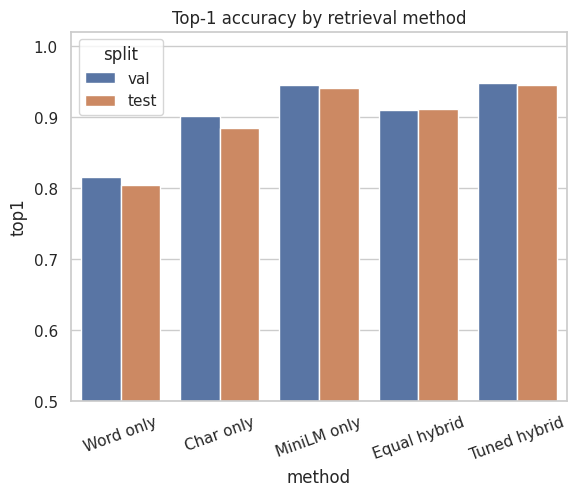

In [10]:
def rank_metrics(S, true_fids, fids):
    # Top-1 / Top-3 (distinct facts) accuracy + best confidence for each query.
    order = np.argsort(-S, axis=1)[:, :40]; top1, top3 = [], []
    for row, t in zip(order, true_fids):
        seen = []
        for j in row:
            if fids[j] not in seen: seen.append(fids[j])
            if len(seen) == 3: break
        top1.append(seen[0] == t); top3.append(t in seen)
    return np.array(top1), np.array(top3), S.max(axis=1), order[:, 0]

fids = train.fact_id.values
Mv = eval_ret.score_matrices(val.question.tolist());  Mt = eval_ret.score_matrices(test.question.tolist())
Ov = eval_ret.score_matrices(ood_val);                Ot = eval_ret.score_matrices(ood_test)

# ---- (a) experimental weight search on VALIDATION (grid, step 0.1) ----
grid = []
for ww in np.arange(0, 1.01, 0.1):
    for wc in np.arange(0, 1.01 - ww, 0.1):
        ws = max(0.0, round(1 - ww - wc, 2))
        if not eval_ret.use_dense and ws > 0: continue
        t1, t3, _, _ = rank_metrics(eval_ret.combine(*Mv, (ww, wc, ws)), val.fact_id.values, fids)
        grid.append(dict(w_word=round(ww,1), w_char=round(wc,1), w_sem=ws, top1=t1.mean(), top3=t3.mean()))
grid = pd.DataFrame(grid).sort_values(["top1","top3"], ascending=False).reset_index(drop=True)
print("Top 8 weight settings on validation:"); display(grid.head(8))
BEST_W = tuple(grid.loc[0, ["w_word","w_char","w_sem"]].astype(float))
print("Selected weights (w_word, w_char, w_sem):", BEST_W)

# ---- (b) single-method baselines vs hybrid (validation and test) ----
cands = {"Word only":(1,0,0), "Char only":(0,1,0), "MiniLM only":(0,0,1), "Equal hybrid":(1/3,1/3,1/3), "Tuned hybrid":BEST_W}
rows = []
for name, w in cands.items():
    if name == "MiniLM only" and not eval_ret.use_dense: continue
    for split_name, M, d in [("val", Mv, val), ("test", Mt, test)]:
        t1, t3, _, _ = rank_metrics(eval_ret.combine(*M, w), d.fact_id.values, fids)
        rows.append(dict(method=name, split=split_name, top1=t1.mean(), top3=t3.mean()))
cmp_df = pd.DataFrame(rows); display(cmp_df.pivot(index="method", columns="split", values=["top1","top3"]).round(4))
sns.barplot(data=cmp_df, x="method", y="top1", hue="split"); plt.xticks(rotation=20); plt.ylim(0.5, 1.02); plt.title("Top-1 accuracy by retrieval method"); plt.show()

Validation sweep (selected rows):


,threshold,precision,recall,f1,rejection_acc,answered_correct
0,0.200,0.966,1.000,0.983,0.200,0.948
3,0.275,0.976,1.000,0.988,0.433,0.948
6,0.350,0.980,1.000,0.990,0.533,0.948
9,0.425,0.987,1.000,0.993,0.700,0.948
12,0.500,0.991,0.999,0.995,0.800,0.946
15,0.575,0.994,0.997,0.996,0.867,0.946
18,0.650,0.997,0.994,0.996,0.933,0.945
21,0.725,1.000,0.978,0.989,1.000,0.933
24,0.800,1.000,0.953,0.976,1.000,0.914
27,0.875,1.000,0.870,0.931,1.000,0.837


Selected threshold on validation = 0.55  (the slide value 0.35 gives:)


,threshold,precision,recall,f1,rejection_acc,answered_correct
0,0.35,0.98,1.0,0.99,0.533,0.948


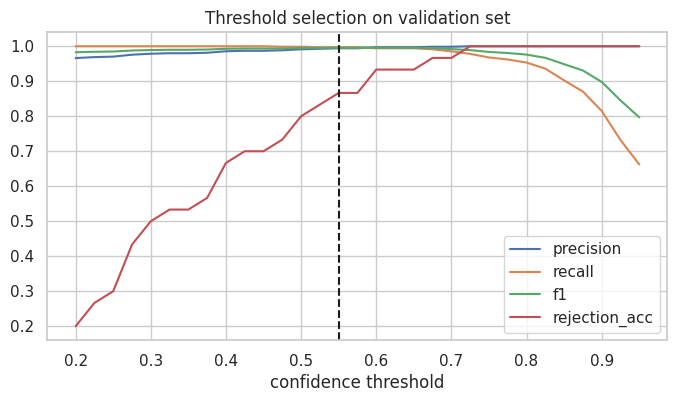

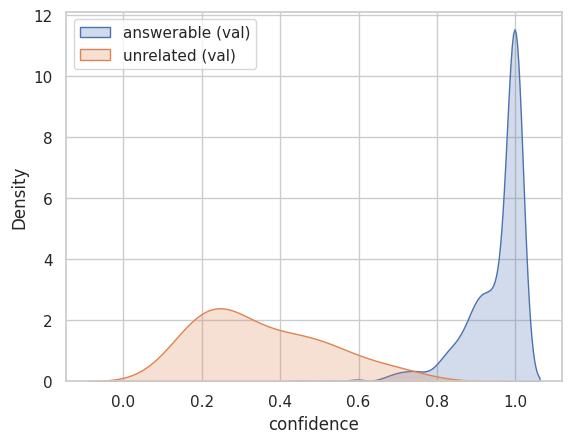

In [11]:
# ---- (c) confidence-threshold sweep on VALIDATION (answerable vs unrelated queries) ----
Sv = eval_ret.combine(*Mv, BEST_W); So = eval_ret.combine(*Ov, BEST_W)
c1, c3, conf_in, _ = rank_metrics(Sv, val.fact_id.values, fids)
conf_out = So.max(axis=1)

def threshold_report(t, conf_in, correct_in, conf_out):
    acc_in, acc_out = conf_in >= t, conf_out >= t
    TP, FN, FP, TN = acc_in.sum(), (~acc_in).sum(), acc_out.sum(), (~acc_out).sum()
    prec = TP/(TP+FP) if TP+FP else 0; rec = TP/(TP+FN); f1 = 2*prec*rec/(prec+rec) if prec+rec else 0
    return dict(threshold=round(t,3), precision=prec, recall=rec, f1=f1, rejection_acc=TN/(TN+FP),
                answered_correct=(acc_in & correct_in).sum()/len(conf_in))

sweep = pd.DataFrame([threshold_report(t, conf_in, c1, conf_out) for t in np.arange(0.20, 0.96, 0.025)])
BEST_T = float(sweep.sort_values(["f1","rejection_acc"], ascending=False).iloc[0].threshold)
print("Validation sweep (selected rows):"); display(sweep.iloc[::3].round(3))
print(f"Selected threshold on validation = {BEST_T}  (the slide value 0.35 gives:)")
display(pd.DataFrame([threshold_report(0.35, conf_in, c1, conf_out)]).round(3))
plt.figure(figsize=(8,4));
for col in ["precision","recall","f1","rejection_acc"]: plt.plot(sweep.threshold, sweep[col], label=col)
plt.axvline(BEST_T, ls="--", c="k"); plt.xlabel("confidence threshold"); plt.legend(); plt.title("Threshold selection on validation set"); plt.show()
sns.kdeplot(conf_in, label="answerable (val)", fill=True); sns.kdeplot(conf_out, label="unrelated (val)", fill=True); plt.xlabel("confidence"); plt.legend(); plt.show()

## Section 8 – Build the Chatbot
The deployed chatbot is indexed on the **full** B.Tech knowledge base with the tuned weights and threshold. Answers are always copied from the CSV; if confidence is below the threshold the fixed *not-available* message is returned.

In [12]:
class CollegeChatbot:
    def __init__(self, df, weights, threshold):
        self.df = df.reset_index(drop=True); self.threshold = threshold; self.weights = weights
        self.ret = HybridRetriever(weights).fit(self.df.question.tolist())
    def answer(self, query, k=3):
        if not isinstance(query, str) or not query.strip():
            return dict(found=False, answer="Please type a question.", matched_question="-", confidence=0.0, category="-", top=[])
        top, sc = self.ret.search(query, k, self.weights); r = self.df.iloc[top[0]]
        res = dict(found=bool(sc[0] >= self.threshold), confidence=float(sc[0]), matched_question=r.question, category=r.category,
                   top=[(self.df.question[i], float(s)) for i, s in zip(top, sc)])
        res["answer"] = r.answer if res["found"] else NOT_FOUND_MSG
        if not res["found"]: res["category"] = "-"
        return res

bot = CollegeChatbot(kb, BEST_W, BEST_T)
for q in ["What is the attendance policy?", "Can I write the exam with 72% attendance?", "Explain the SGPA calculation", "What is the weather today?"]:
    r = bot.answer(q); print(f"\nQ: {q}\nFOUND={r['found']} conf={r['confidence']:.2f} cat={r['category']}\nA: {r['answer'][:230]}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Q: What is the attendance policy?
FOUND=True conf=1.00 cat=Attendance
A: Students are generally required to maintain at least 75% attendance to be eligible for examinations. Attendance eligibility is checked separately for each subject according to the applicable institutional regulations. Students bel

Q: Can I write the exam with 72% attendance?
FOUND=True conf=0.96 cat=Attendance
A: Sample rule: 72% (or any value from 65% up to below 75%) is below the 75% requirement, so you are not automatically eligible. You can apply for attendance condonation with valid proof (for example a medical certificate) and pay th

Q: Explain the SGPA calculation
FOUND=True conf=1.00 cat=Academic Regulations
A: SGPA (Semester Grade Point Average) = sum of (credits x grade points) of all courses in the semester divided by the total credits of the semester. Example: courses with credits 4, 3, 3 and grade points 9, 8, 10 give (36 + 24 + 30)

Q: What is the weather today?
FOUND=False conf=0.18 cat=-
A: Sorr

In [13]:
try:                                    # lets widgets display in new Colab versions
    from google.colab import output; output.enable_custom_widget_manager()
except Exception: pass
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
import html as _html

def build_ui(bot):
    history = widgets.Output(layout=widgets.Layout(border="1px solid #cbd5e1", padding="8px", max_height="460px", overflow_y="auto"))
    box = widgets.Text(placeholder="Ask about attendance, exams, SGPA, fees, first-semester syllabus...", layout=widgets.Layout(width="70%"))
    btn = widgets.Button(description="Ask", button_style="primary", icon="search")
    examples = ["What is the attendance policy?", "What is the minimum attendance required for semester exams?", "Explain the SGPA calculation",
                "What are the subjects in the first semester?", "What is Unit 1 in my mathematics syllabus?", "What is the revaluation procedure?"]
    def show(q):
        try:
            r = bot.answer(q); e = _html.escape
            color = "#e8f7ee" if r["found"] else "#fdecea"
            meta = (f"<b>Matched KB question:</b> {e(r['matched_question'])}<br><b>Category:</b> {e(r['category'])} &nbsp;|&nbsp; <b>Confidence:</b> {r['confidence']:.2f}"
                    if r["found"] else f"<b>Confidence:</b> {r['confidence']:.2f} (below threshold {bot.threshold})")
            with history:
                display(HTML(f"<div style='background:#e0e7ff;padding:8px;border-radius:8px;margin:6px 0'>🧑 <b>{e(q)}</b></div>"
                             f"<div style='background:{color};padding:10px;border-radius:8px;margin:6px 0 14px'>🤖 {e(r['answer'])}<hr style='margin:6px 0'><small>{meta}</small></div>"))
        except Exception as ex:
            with history: print("Something went wrong:", ex)
    def on_ask(_):
        q = box.value.strip()
        if q: show(q); box.value = ""
    btn.on_click(on_ask)
    try: box.on_submit(on_ask)          # only exists in older ipywidgets; Enter key is optional, the Ask button always works
    except Exception: pass
    chips = []
    for ex in examples:
        b = widgets.Button(description=ex, layout=widgets.Layout(width="auto")); b.on_click(lambda _, t=ex: show(t)); chips.append(b)
    display(HTML("<h2 style='color:#1e3a8a'>🎓 College Regulations & Syllabus Assistant</h2><p>Hello! Ask me about attendance, examinations, grading, fees, hostel, library and the <b>first-semester B.Tech syllabus</b>. "
                 "<i>(Prototype data is SAMPLE – confirm with the Academic Office.)</i></p><b>Try an example:</b>"))
    display(widgets.VBox([widgets.HBox(chips[:3]), widgets.HBox(chips[3:])]), widgets.HBox([box, btn]), history)
build_ui(bot)

# ---- Simple fallback that ALWAYS works (no widgets needed) ----
def ask(question):
    r = bot.answer(question)
    print("Q:", question); print("A:", r["answer"])
    if r["found"]: print(f"   [category: {r['category']} | confidence: {r['confidence']:.2f}]")
    else: print(f"   [confidence {r['confidence']:.2f} below threshold {bot.threshold}]")
    print()
ask("What is the minimum attendance required?")

Output(layout=Layout(border='1px solid #cbd5e1', max_height='460px', overflow_y='auto', padding='8px'))

Q: What is the minimum attendance required?
A: Students are generally required to maintain at least 75% attendance to be eligible for examinations. Attendance eligibility is checked separately for each subject according to the applicable institutional regulations. Students below the prescribed requirement may need to follow the official condonation or shortage procedure, if permitted. [Sample rule for this prototype - replace with the official college regulation.]
   [category: Attendance | confidence: 1.00]



### Chat with the bot
Run the cell below, type a question in the box that appears, press Enter. Type `exit` to stop.

In [14]:
# ---- Chat in the notebook (no widgets needed). Type 'exit' to stop. ----
while True:
    q = input("You: ").strip()
    if q.lower() in {"exit", "quit", "q", ""}: print("Bye!"); break
    ask(q)

You: what is attendance policy
Q: what is attendance policy
A: Students are generally required to maintain at least 75% attendance to be eligible for examinations. Attendance eligibility is checked separately for each subject according to the applicable institutional regulations. Students below the prescribed requirement may need to follow the official condonation or shortage procedure, if permitted. [Sample rule for this prototype - replace with the official college regulation.]
   [category: Attendance | confidence: 0.98]

You: exit
Bye!


## Section 9 – Testing
60 realistic queries: exact, paraphrased, misspelt, short, long, unrelated, syllabus, attendance and examination. A prediction is **correct** if the retrieved category is the expected one *and* the answer contains the expected key phrase (for unrelated queries: correct = rejected).

In [15]:
T = [  # (query, expected category, key phrase expected in the answer, type)
("What is the attendance policy?","Attendance","75%","exact"),("What is the minimum attendance required?","Attendance","75%","exact"),
("How much attendance is compulsory?","Attendance","75%","paraphrase"),("Is 75% attendance mandatory?","Attendance","75%","exact"),
("Can I write semester exams with 72% attendance?","Attendance","condonation","exact"),("I have 72% attendance can i write exam","Attendance","condonation","paraphrase"),
("What happens if my attendance is below 75%?","Attendance","condon","exact"),("What is attendance condonation?","Attendance","condonation","exact"),
("min attendence for sem exams","Attendance","75%","spelling"),("attendence rules","Attendance","75%","spelling"),
("Is attendance compulsory for mid exams?","Attendance","mid","paraphrase"),("how to calculate attendance percentage","Attendance","100","paraphrase"),
("attendance","Attendance","75%","short"),
("Is attendance calculated separately for every subject?","Attendance","separately","exact"),
("Can medical certificate help if my attendance is short?","Attendance","medical","paraphrase"),
("Does attendance affect internal marks?","Attendance","internal","exact"),
("What is the revaluation procedure?","Examination","revaluation","exact"),("how to apply for reval","Examination","revaluation","short"),
("revalution fee","Examination","1,000","spelling"),("What is the difference between recounting and revaluation?","Examination","recount","paraphrase"),
("What are the malpractice rules in exams?","Examination","malpractice","exact"),("Can I take my mobile phone into the exam hall?","Examination","mobile","paraphrase"),
("How do I download my hall ticket?","Examination","hall ticket","paraphrase"),("what are supplementary exams","Examination","supplementary","short"),
("I failed a subject, how do I clear the backlog?","Examination","backlog","long"),("What is the pass mark for a theory subject?","Examination","28","paraphrase"),
("How are internal marks calculated?","Examination","30","paraphrase"),("what is the improvement exam","Examination","improvement","short"),
("Explain the SGPA calculation","Academic Regulations","SGPA","exact"),("how to calculate cgpa","Academic Regulations","CGPA","paraphrase"),
("What is the grading system?","Academic Regulations","A+","exact"),("what is academic probation","Academic Regulations","probation","short"),
("What is detention in college?","Academic Regulations","detain","paraphrase"),("How many credits are needed for B.Tech?","Academic Regulations","160","paraphrase"),
("What are mandatory courses?","Academic Regulations","non-credit","exact"),
("How do I get a bonafide certificate?","College Administration","bonafide","exact"),("how to get transfer certificate","College Administration","transfer certificate","paraphrase"),
("What is the hostel in time?","College Administration","8:00 PM","exact"),("how many books can i borrow from library","College Administration","3 books","paraphrase"),
("How do I apply for scholarships?","College Administration","scholarship","exact"),("I forgot my student portal password","College Administration","password","paraphrase"),
("How can I pay my college fees online?","College Administration","portal","paraphrase"),
("I lost a library book, what should I do?","Practical Student Problems","replace","long"),("What if I miss a mid exam due to illness and want a re-test?","Practical Student Problems","HOD","long"),
("I missed the lab session, what now?","Practical Student Problems","make-up","paraphrase"),("Where can I see the academic calendar?","Practical Student Problems","calendar","exact"),
("What are the subjects in the first semester?","Syllabus","Mathematics-I","exact"),("1st sem subjects","Syllabus","Mathematics-I","short"),
("What is Unit 1 in my mathematics syllabus?","Syllabus","Unit 1","exact"),("unit 3 of physics","Syllabus","Unit 3","short"),
("what is unit 5 in c programming","Syllabus","Unit 5","paraphrase"),("How many credits are there in first semester?","Syllabus","Total","exact"),
("What laboratory subjects are there in first semester?","Syllabus","Laborator","paraphrase"),("What is Cayley-Hamilton theorem?","Syllabus","characteristic","exact"),
("what is numerical aperture","Syllabus","NA","short"),
("What is the weather today?","REJECTED","","unrelated"),("Who won the cricket match yesterday?","REJECTED","","unrelated"),
("How do I bake a cake?","REJECTED","","unrelated"),("What is the syllabus of Operating Systems?","REJECTED","","unrelated"),
("Tell me a joke","REJECTED","","unrelated"),("Which movie should I watch tonight?","REJECTED","","unrelated"),
]
rows = []
for q, ecat, key, kind in T:
    r = bot.answer(q); pred = r["category"] if r["found"] else "REJECTED"
    ok = (pred == "REJECTED") if ecat == "REJECTED" else (pred == ecat and key.lower() in r["answer"].lower())
    rows.append(dict(query=q, type=kind, expected_category=ecat, retrieved_category=pred, retrieved_answer=r["answer"][:110]+"...", confidence=round(r["confidence"],3), correct=ok))
test_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120); display(test_df)
print(f"\nManual test accuracy: {test_df.correct.mean():.1%} ({test_df.correct.sum()}/{len(test_df)})")
display(test_df.groupby("type").correct.agg(["mean","count"]).round(3))

,query,type,expected_category,retrieved_category,retrieved_answer,confidence,correct
0,What is the attendance policy?,exact,Attendance,Attendance,Students are generally required to maintain at least 75% attendance to be eligible for examinations. Attendanc...,1.000,True
1,What is the minimum attendance required?,exact,Attendance,Attendance,Students are generally required to maintain at least 75% attendance to be eligible for examinations. Attendanc...,1.000,True
2,How much attendance is compulsory?,paraphrase,Attendance,Attendance,Students are generally required to maintain at least 75% attendance to be eligible for examinations. Attendanc...,1.000,True
3,Is 75% attendance mandatory?,exact,Attendance,Attendance,Students are generally required to maintain at least 75% attendance to be eligible for examinations. Attendanc...,1.000,True
4,Can I write semester exams with 72% attendance?,exact,Attendance,Attendance,"Sample rule: 72% (or any value from 65% up to below 75%) is below the 75% requirement, so you are not automati...",1.000,True
...,...,...,...,...,...,...,...
56,Who won the cricket match yesterday?,unrelated,REJECTED,REJECTED,"Sorry, this information is not available in the current college knowledge base. Please contact the Academic Of...",0.215,True
57,How do I bake a cake?,unrelated,REJECTED,REJECTED,"Sorry, this information is not available in the current college knowledge base. Please contact the Academic Of...",0.242,True
58,What is the syllabus of Operating Systems?,unrelated,REJECTED,Syllabus,"Engineering Graphics (SAMPLE-ME106, 2 credits). Units: Unit 1: Introduction to drawing: lettering, dimensionin...",0.619,False
59,Tell me a joke,unrelated,REJECTED,REJECTED,"Sorry, this information is not available in the current college knowledge base. Please contact the Academic Of...",0.199,True



Manual test accuracy: 95.1% (58/61)


,mean,count
type,,
exact,1.000,21
long,0.667,3
paraphrase,1.000,20
short,1.000,8
spelling,0.667,3
unrelated,0.833,6


## Section 10 – Results and Discussion
All numbers below are produced by running this notebook; nothing is hard-coded. Final scores use the **held-out test split** with weights/threshold chosen on validation.

,metric,value
0,Top-1 accuracy (answerable),0.9447
1,Top-3 accuracy (answerable),0.9651
2,Answer-vs-reject precision,0.9956
3,Answer-vs-reject recall,0.9956
4,Answer-vs-reject F1,0.9956
5,Rejection accuracy (unrelated),0.9000
6,Answered AND correct (answerable),0.9432


Weights = (0.0, 0.1, 0.9) | threshold = 0.55 | test queries: 687 answerable + 30 unrelated
Average response time: 27.0 ms per query


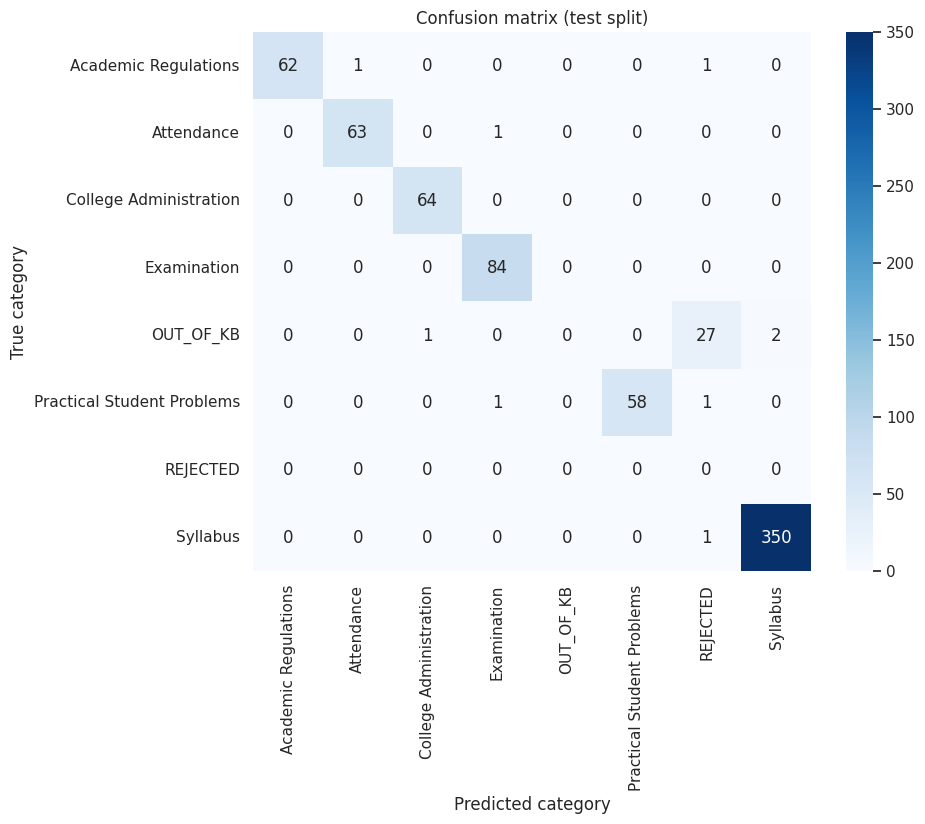

Wrong top-1 on test: 38


,question,category,retrieved_question,retrieved_category
2,unit 1 of linear algebra and calculus,Syllabus,Unit 2 of linear algebra and calculus,Syllabus
43,"can you tell me i missed my internal exam, what to do for btech",Practical Student Problems,One doubt: i missed my semester exam what to do for btech,Examination
45,Engineering physics unit 5 topics,Syllabus,Sir engineering physics unit 4 topics,Syllabus
46,Doubt: enginering physics lab course code pls,Syllabus,Sir enginering physics subject code ?,Syllabus
48,Eng unit 3 topics,Syllabus,eng unit 2 topics,Syllabus
58,Tell me enginering physics unit 4 topics in first year,Syllabus,I want to know eng physics unit 2 topics in first year,Syllabus
102,I want to know eng unit 4 topics,Syllabus,Eng unit 5 topics,Syllabus
110,doubt: what are the subjects in the first semister?,Syllabus,hi Wat are the course outcomes of the first semister?,Syllabus
121,Drawing unit 4 topics,Syllabus,Drawing unit 3 topics,Syllabus
139,"Hello, unit 1 of pyhsics pls",Syllabus,tell me units in pysics,Syllabus


Unrelated queries wrongly answered: [('What is Unit 3 of Machine Learning?', 0.623), ('What is the syllabus of Data Structures?', 0.59), ('Is there wifi in the hostel rooms?', 0.589)]


In [16]:
# ---- Held-out TEST evaluation ----
St = eval_ret.combine(*Mt, BEST_W); So_t = eval_ret.combine(*Ot, BEST_W)
t1, t3, conf_t, best_idx = rank_metrics(St, test.fact_id.values, fids); conf_o = So_t.max(axis=1)
rep = threshold_report(BEST_T, conf_t, t1, conf_o)
res = pd.DataFrame({"metric":["Top-1 accuracy (answerable)","Top-3 accuracy (answerable)","Answer-vs-reject precision","Answer-vs-reject recall","Answer-vs-reject F1","Rejection accuracy (unrelated)","Answered AND correct (answerable)"],
                    "value":[t1.mean(), t3.mean(), rep["precision"], rep["recall"], rep["f1"], rep["rejection_acc"], rep["answered_correct"]]})
display(res.round(4)); print(f"Weights = {BEST_W} | threshold = {BEST_T} | test queries: {len(test)} answerable + {len(ood_test)} unrelated")

# ---- Response time on the deployed chatbot ----
qs = test.question.sample(min(100, len(test)), random_state=SEED).tolist(); t0 = time.perf_counter()
for q in qs: bot.answer(q)
print(f"Average response time: {(time.perf_counter()-t0)/len(qs)*1000:.1f} ms per query")

# ---- Category-level confusion matrix (test + unrelated, after thresholding) ----
true_lab = list(test.category) + ["OUT_OF_KB"] * len(ood_test)
pred_lab = [train.category[j] if c >= BEST_T else "REJECTED" for j, c in zip(best_idx, conf_t)] + \
           [train.category[j] if c >= BEST_T else "REJECTED" for j, c in zip(So_t.argmax(axis=1), conf_o)]
labs_t = sorted(set(true_lab)); labs_p = sorted(set(pred_lab) | set(train.category))
cm = confusion_matrix(true_lab, pred_lab, labels=sorted(set(labs_t) | set(labs_p)))
plt.figure(figsize=(9,7)); sns.heatmap(pd.DataFrame(cm, index=sorted(set(labs_t)|set(labs_p)), columns=sorted(set(labs_t)|set(labs_p))), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted category"); plt.ylabel("True category"); plt.title("Confusion matrix (test split)"); plt.show()

# ---- Error analysis: show wrong top-1 retrievals ----
wrong = test[~t1].copy(); wrong["retrieved_question"] = [train.question[j] for j in best_idx[~t1]]; wrong["retrieved_category"] = [train.category[j] for j in best_idx[~t1]]
print(f"Wrong top-1 on test: {len(wrong)}"); display(wrong[["question","category","retrieved_question","retrieved_category"]].head(10))
fp = [(q, round(float(c),3)) for q, c in zip(ood_test, conf_o) if c >= BEST_T]; print("Unrelated queries wrongly answered:", fp)

### Discussion
* Compare the **word-only**, **char-only**, **MiniLM-only** and **hybrid** rows in Section 7: they show how much each component contributes on *this* dataset, and the weights were selected from a grid rather than assumed.
* The threshold is selected from the validation sweep; the value used in earlier slides (0.35) is shown beside it for comparison.
* Held-out queries are *variants of the same facts* (typos, informal wording), so test accuracy measures robustness to wording, not to completely new facts. The manual test set (Section 9) is a separate sanity check.
* Remaining errors typically involve near-identical questions (e.g. mid-exam vs semester-exam attendance) and hard-negative queries that look like college questions but are absent from the KB.

In [17]:
# ---- Save the indexed artifacts of the deployed chatbot ----
import joblib
os.makedirs("rag_artifacts", exist_ok=True)
joblib.dump({"word": bot.ret.word_vec, "char": bot.ret.char_vec, "weights": BEST_W, "threshold": BEST_T}, "rag_artifacts/vectorizers.joblib")
kb.drop(columns=["split"]).to_csv("rag_artifacts/knowledge_base_used.csv", index=False)
if bot.ret.use_dense:
    np.save("rag_artifacts/question_embeddings.npy", bot.ret.E)
    if HAS_FAISS: faiss.write_index(bot.ret.index, "rag_artifacts/faiss.index")
print("Saved:", os.listdir("rag_artifacts"))

Saved: ['faiss.index', 'knowledge_base_used.csv', 'question_embeddings.npy', 'vectorizers.joblib']


## Section 11 – Limitations and Future Scope
**Limitations**
* **Dataset quality dependence** – answers are only as correct as the CSV.
* **Sample institutional regulations/syllabus** – 75 % attendance, fees, grading, subject names, course codes and unit titles are placeholders until replaced with official documents.
* **Limited semester coverage** – only B.Tech first semester; other institution types are small labelled samples.
* **Similarity-based retrieval errors** – near-identical questions (72 % vs 75 %) or hard-negative queries can be matched wrongly.
* **Multilingual limitation** – English only (no Telugu/Hindi).
* **No personal student data** – cannot tell *your* attendance or marks; no conversation memory.

**Future scope:** official PDF ingestion · Telugu & Hindi support · voice input · LLM-based answer generation *with citations to retrieved records* · all-semester syllabus · website/WhatsApp deployment · college database integration.

## Section 12 – Conclusion
A hybrid retriever (TF-IDF word + char 3–5-gram + MiniLM/FAISS) over a categorised, deduplicated knowledge base answers student questions only with stored CSV text and refuses unrelated queries via a validation-selected confidence threshold. Quantitative claims should be taken from the output of Sections 7, 9 and 10 of your own run. Before real use, replace the sample regulations and syllabus with official college documents.